# Central limit theorem for Gaussian random number generator

Lecture 2 (16/11) - Monte Carlo methods

## Exercise

1. Generate $10^8$ sets of $n$ uniformly distributed random numbers in $[-1, 1]$, with $n = 1, 2, \dots, 10$.
2. For every $n$, populate a histogram with the $10^8$ sums of the $n$ generated random numbers.
3. Plot the histogram in linear and log-scale (on the $y$ axis). Do you notice anything?
4. Compare with a Gaussian.

## Solution

In [34]:
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm, uniform

### Functions

In [38]:
def mean_histogram(n, n_sets, bins, rng, chunk=10**6):
    """Histogram of the mean of n uniform numbers in [-1, 1], repeated n_sets times."""
    counts = np.zeros(len(bins) - 1, dtype=np.float64)

    for _ in range(n_sets // chunk):
        xbar = rng.uniform(-1, 1, (chunk, n)).mean(axis=1)
        counts += np.histogram(xbar, bins=bins)[0]

    return counts

### Plots

In [39]:
# Data
n_sets = 10**8
ns = np.arange(1, 11)
bins = np.linspace(-1, 1, 201)               # 200 bins
xc = 0.5 * (bins[1:] + bins[:-1])
w = bins[1] - bins[0]
rng = np.random.default_rng(12345)

In [40]:
counts = {}

for n in ns:
    counts[n] = mean_histogram(n, n_sets, bins, rng)

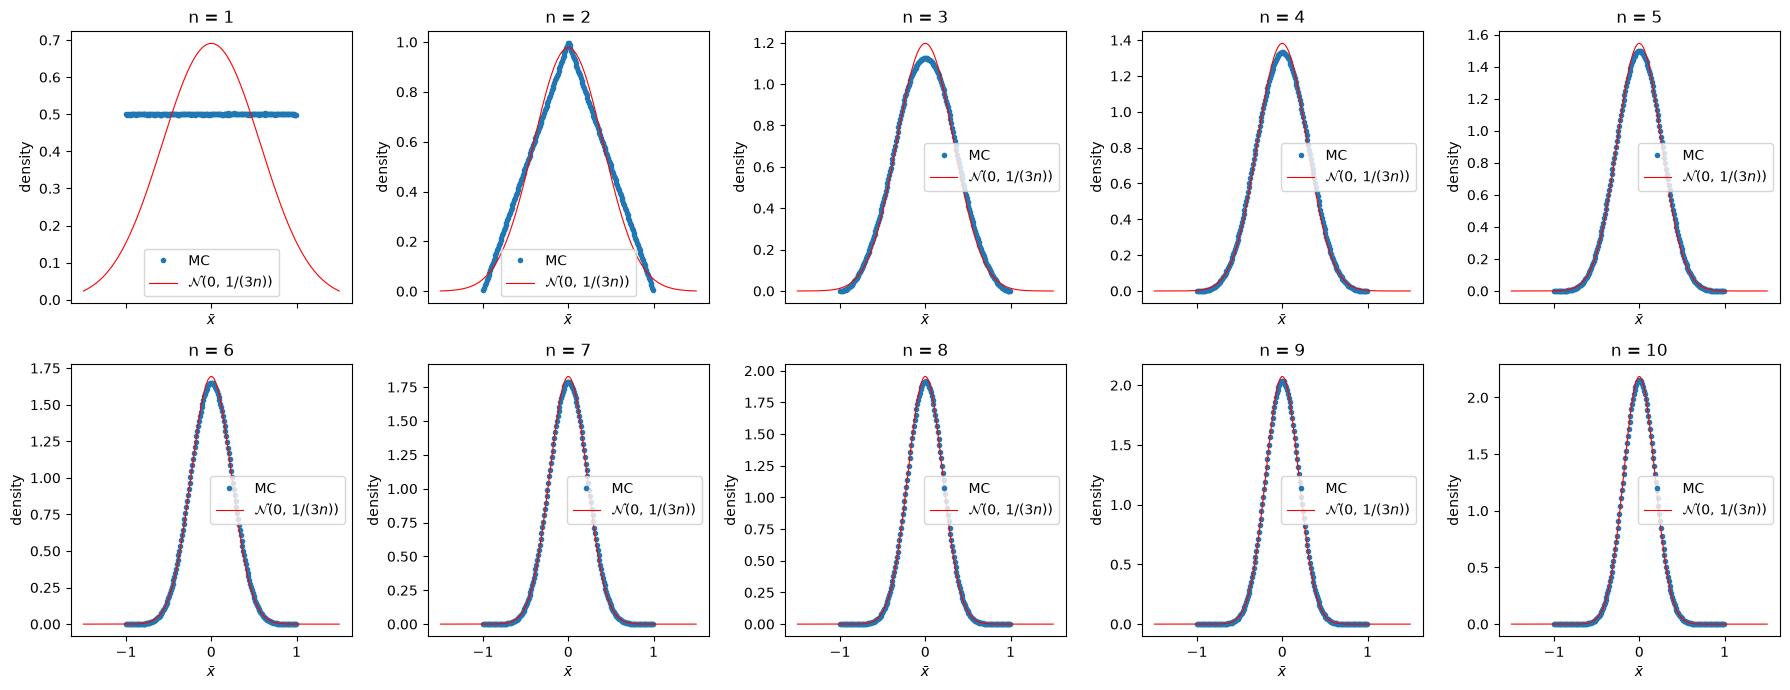

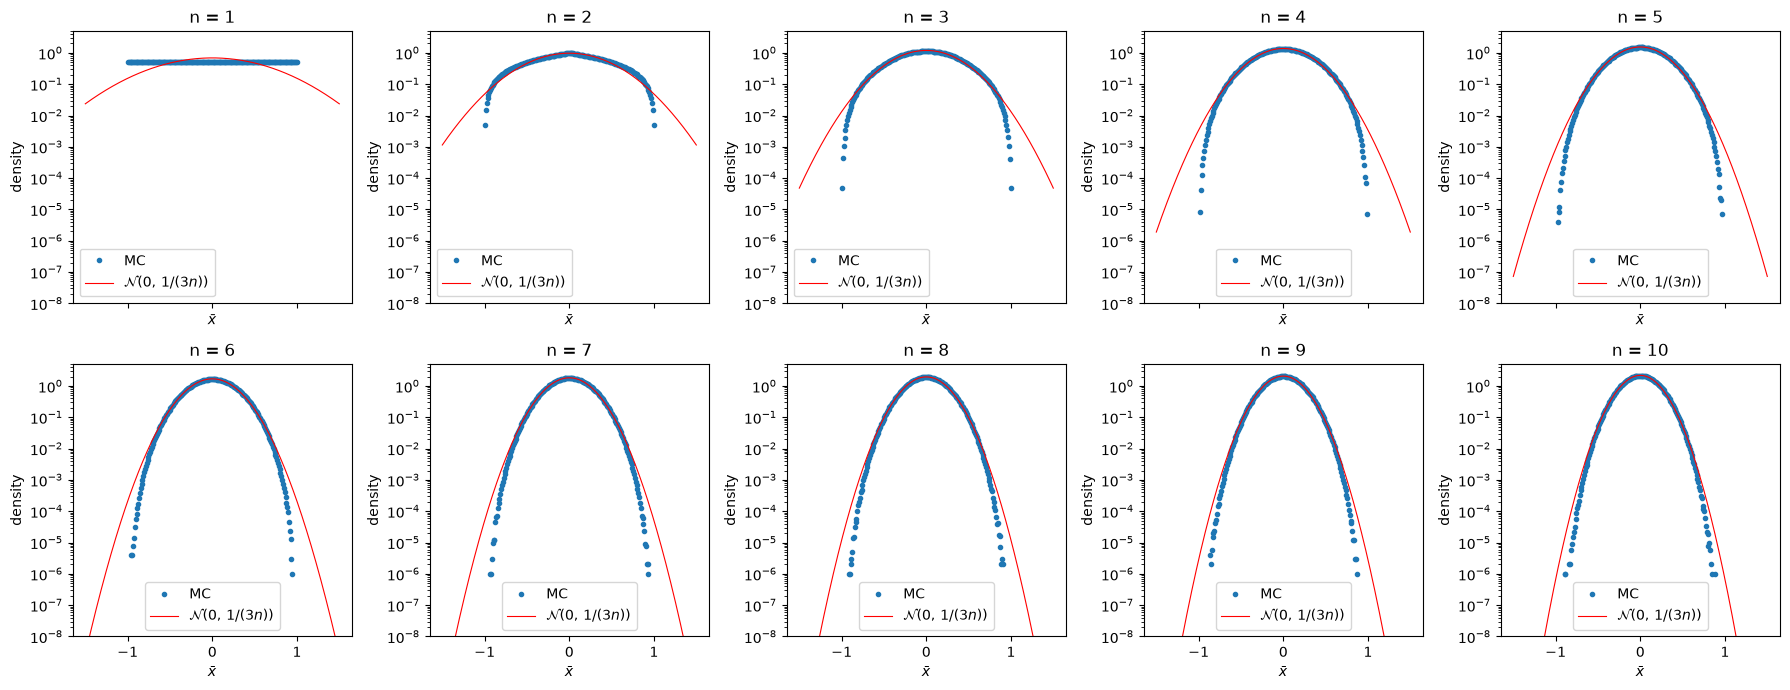

In [42]:
xx = np.linspace(-1.5, 1.5, 1000)

for scale in ("linear", "log"):
    fig, axes = plt.subplots(2, 5, figsize=(18, 7), sharex=True)

    for ax, n in zip(axes.flat, ns):
        sigma = 1 / np.sqrt(3 * n)
        dens = counts[n] / (n_sets * w)

        ax.plot(xc, dens,"o", ms=3, label="MC")
        ax.plot(xx, norm.pdf(xx, 0, sigma), "r-", lw=0.8, label=r"$\mathcal{N}(0,\,1/(3n))$")

        ax.set_yscale(scale)
        if scale == "log":
            ax.set_ylim(1e-8, 5)

        ax.set_title(f"n = {n}")
        ax.set_xlabel(r"$\bar{x}$"); ax.set_ylabel("density")
        ax.legend()

    fig.tight_layout()

plt.show()

## Conclusions

- **Convergence.** The distribution of $\bar x$ is flat for $n=1$, triangular
  for $n=2$ and already close to a Gaussian in the central region for
  $n\gtrsim4$. The variance matches $1/3n$ exactly, as expected.
- **Tails (log scale).** The deviations are visible in the tails: $\bar x$ is
  bounded in $[-1,1]$, while the Gaussian is not. This is why this is an
  *inefficient* (and approximate) Gaussian generator: it needs $n$ uniform
  numbers per Gaussian number and does not reproduce the far tails.

